<a href="https://colab.research.google.com/github/agugun/axscnt-notebook/blob/main/partial_differential_eq/Wave_Equation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Wave Equation: 1D and 2D

**PDE type: hyperbolic** (see the classification table in `README.md`)

$$\frac{\partial^2 u}{\partial t^2} = c^2\,\nabla^2 u$$

**Where it comes from:** take a small piece of a stretched string or membrane. Tension pulls it back toward the average position of its neighbours, with a force proportional to $\nabla^2 u$ (the Laplacian from the differential notebook). Newton's second law, mass $\times$ acceleration = force, gives the equation above with wave speed $c = \sqrt{\text{tension} / \text{density}}$.

**Same Laplacian as the heat equation, very different behaviour:**

| | Heat (diffusion) | Wave |
|---|---|---|
| equation | $\partial_t u = \alpha\nabla^2 u$ | $\partial_t^2 u = c^2\nabla^2 u$ |
| $\nabla^2 u$ sets the | **velocity** of change | **acceleration** |
| a bump | spreads out and flattens | splits into pulses that travel at speed $c$ |
| at a fixed edge | heat drains out | the pulse reflects, upside down |
| energy | decreases (flows out of the edges) | conserved: $E = \tfrac12\int (u_t^2 + c^2|\nabla u|^2)$ |
| initial data needed | $u(x, 0)$ | $u(x, 0)$ **and** $u_t(x, 0)$ |

| Part | Domain | Methods |
|---|---|---|
| 1 | string, $0 \le x \le L$ | explicit central differences, d'Alembert travelling waves, energy check |
| 2 | square membrane | explicit 5-point scheme, double Fourier series, energy check |
| 3 | heat vs wave | the same initial bump under both equations |

## Part 1: 1D wave equation (string)

$$\frac{\partial^2 u}{\partial t^2} = c^2 \frac{\partial^2 u}{\partial x^2}, \qquad u(0, t) = u(L, t) = 0, \qquad u(x, 0) = f(x), \quad u_t(x, 0) = 0$$

A string of length $L = 10$ with wave speed $c = 1.5$, plucked near $x = 3$ and released from rest.

**Explicit scheme** (central differences in time and space):

$$u_i^{n+1} = 2u_i^n - u_i^{n-1} + C^2\left(u_{i+1}^n - 2u_i^n + u_{i-1}^n\right), \qquad C = \frac{c\,\Delta t}{\Delta x} \le 1$$

$C \le 1$ is the **CFL condition**: in one time step a wave must not travel further than one grid cell.

**Exact solution (d'Alembert):** the initial shape splits into two halves that travel in opposite directions,

$$u(x, t) = \tfrac12\left[f(x - ct) + f(x + ct)\right],$$

with $f$ extended as an odd, $2L$-periodic function, which makes the fixed ends reflect pulses upside down. After one period $T = 2L/c$ the string is back in its starting shape.

In [1]:
# 1D WAVE EQUATION: explicit solver, d'Alembert exact solution, energy
import numpy as np

trap = getattr(np, 'trapezoid', None) or getattr(np, 'trapz')

# 1. Physical and numerical parameters
L = 10.0                 # string length
c = 1.5                  # wave speed
Nx = 201
x = np.linspace(0, L, Nx)
dx = x[1] - x[0]
T_period = 2 * L / c     # time for a pulse to go to both ends and back
dt = 0.9 * dx / c        # Courant number about 0.9 (must be <= 1)
Nt = int(np.ceil(T_period / dt))
dt = T_period / Nt
C = c * dt / dx
t = np.linspace(0, T_period, Nt + 1)
print(f"1D explicit solver -> dx = {dx:.3f}, dt = {dt:.4f}, steps = {Nt}, Courant C = {C:.3f} (limit 1)")


# 2. Initial condition: a plucked bump, released from rest
def f0(s):
    return 2.0 * np.exp(-((s - 3.0)**2) / 0.3)


u = np.zeros((Nt + 1, Nx))
u[0] = f0(x)
u[0, [0, -1]] = 0.0
# First step uses u_t(x, 0) = 0:  u^1 = u^0 + (C^2 / 2) (u_{i+1} - 2 u_i + u_{i-1})
u[1, 1:-1] = u[0, 1:-1] + 0.5 * C**2 * (u[0, 2:] - 2 * u[0, 1:-1] + u[0, :-2])

# 3. Time stepping
for n in range(1, Nt):
    u[n + 1, 1:-1] = 2 * u[n, 1:-1] - u[n - 1, 1:-1] + C**2 * (u[n, 2:] - 2 * u[n, 1:-1] + u[n, :-2])


# 4. d'Alembert exact solution with odd 2L-periodic extension (fixed ends)
def f_ext(s):
    s = np.mod(s, 2 * L)
    return np.where(s <= L, f0(s), -f0(2 * L - s))


def dalembert(xx, tt):
    return 0.5 * (f_ext(xx - c * tt) + f_ext(xx + c * tt))


u_exact = dalembert(x[None, :], t[:, None])

# 5. Energy at half steps t_{n+1/2}: kinetic 1/2 int u_t^2 dx + potential 1/2 c^2 int u_x^2 dx
#    (the potential term uses slopes at the two neighbouring time levels; this is the form
#     the explicit scheme conserves exactly)
ut_half = (u[1:] - u[:-1]) / dt
KE = 0.5 * np.sum(ut_half**2, axis=1) * dx
PE = 0.5 * c**2 * np.sum(np.diff(u[1:], axis=1) * np.diff(u[:-1], axis=1), axis=1) / dx
E = KE + PE
t_half = 0.5 * (t[1:] + t[:-1])

print(f"max |explicit - d'Alembert| over all times = {np.abs(u - u_exact).max():.4f}  (bump height {f0(3):.1f})")
print(f"after one period T = 2L/c: max |u(T) - u(0)| = {np.abs(u[-1] - u[0]).max():.4f}")
print(f"energy: start {E[0]:.5f}, min {E.min():.5f}, max {E.max():.5f}  "
      f"-> relative change {(E.max() - E.min()) / E[0]:.1e}")

1D explicit solver -> dx = 0.050, dt = 0.0300, steps = 445, Courant C = 0.899 (limit 1)
max |explicit - d'Alembert| over all times = 0.0186  (bump height 2.0)
after one period T = 2L/c: max |u(T) - u(0)| = 0.0007
energy: start 10.22396, min 10.22396, max 10.22396  -> relative change 2.6e-15


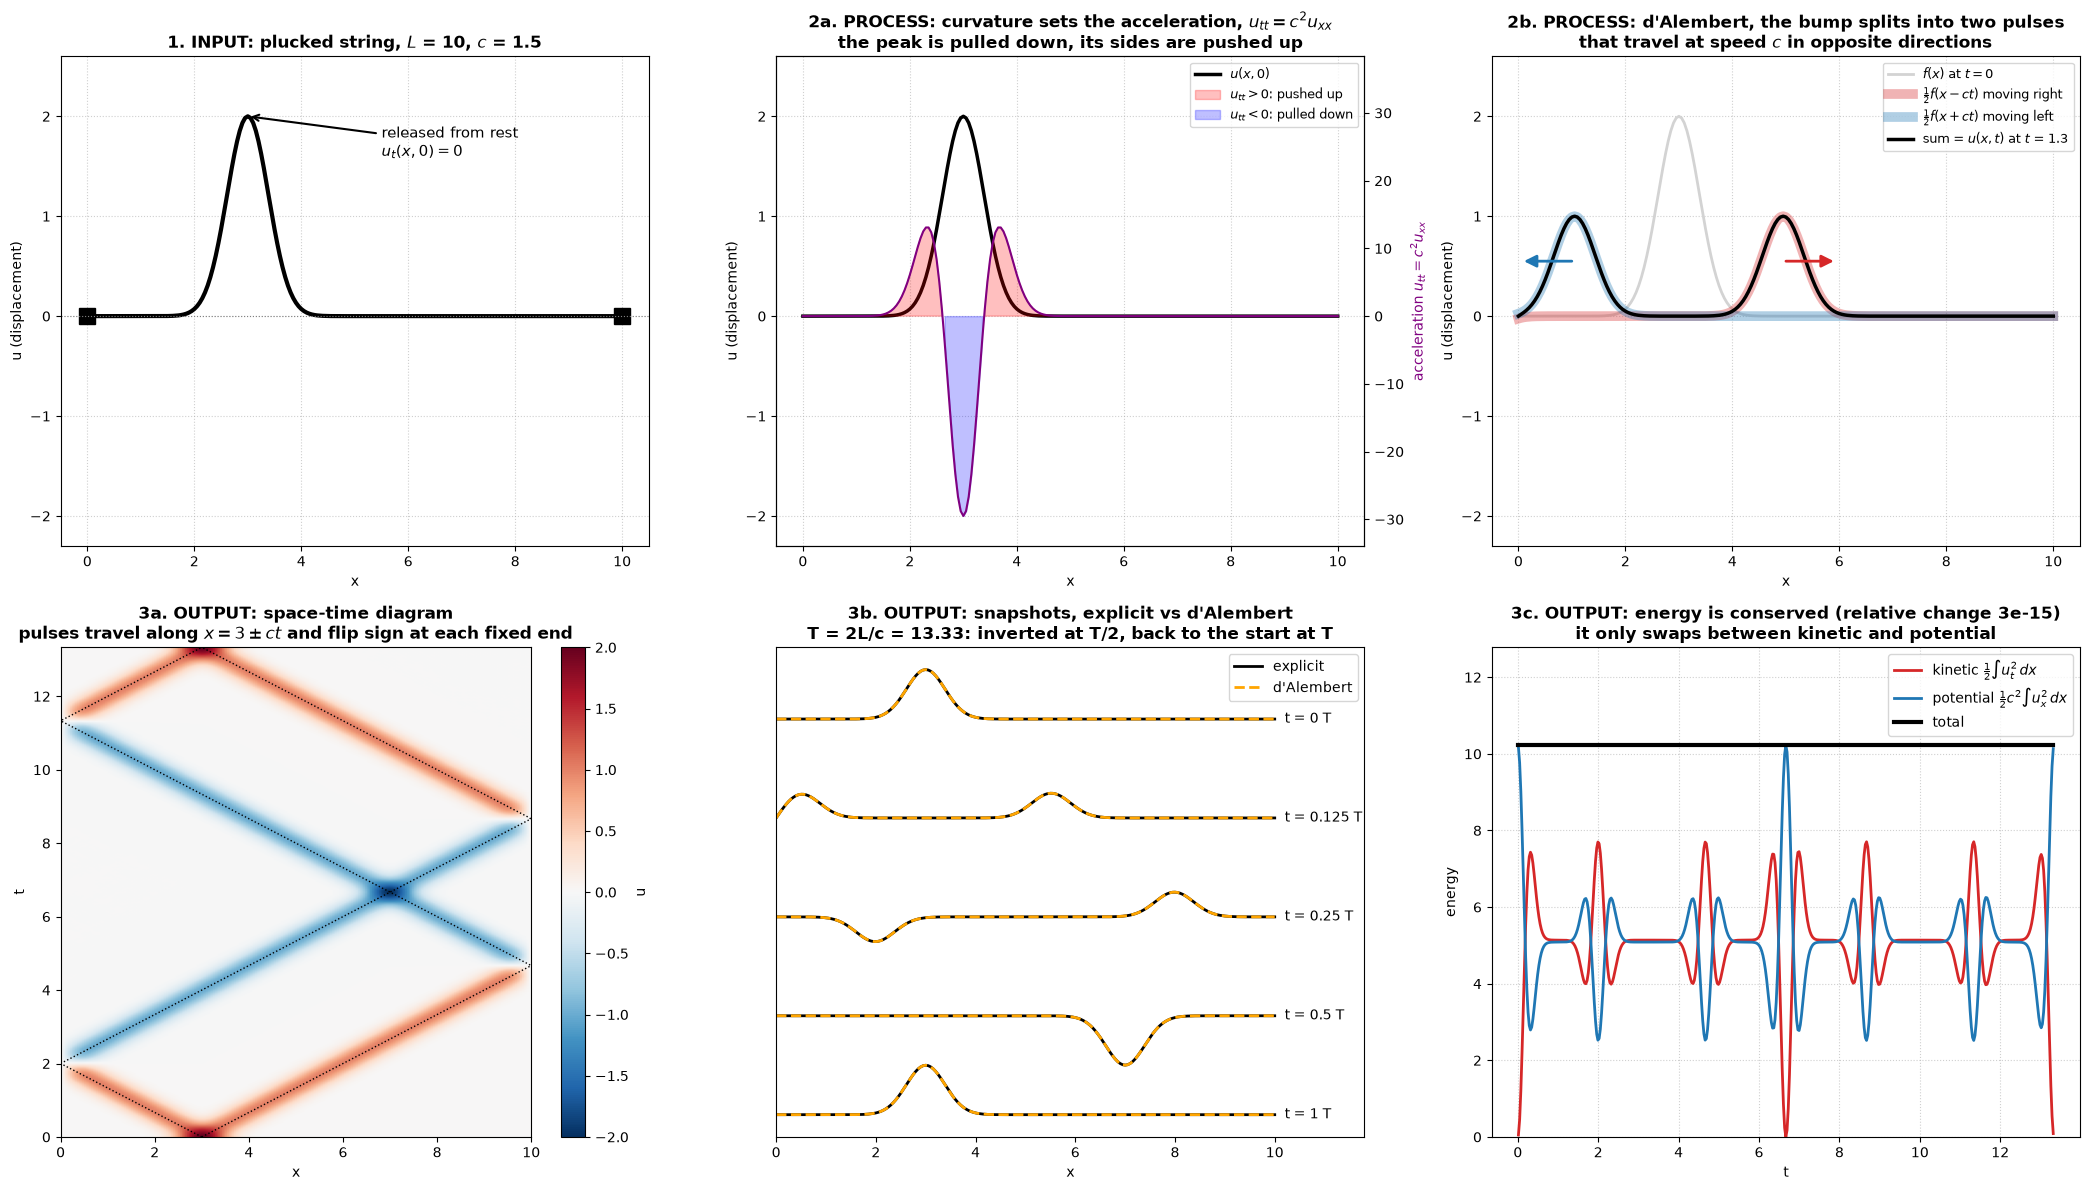

In [2]:
# 1D WAVE EQUATION: INPUT -> PROCESS -> OUTPUT
import numpy as np
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 3, figsize=(21, 12))
u_xx0 = np.gradient(np.gradient(u[0], dx), dx)


def fold(p):
    # Position of a pulse moving on [0, L] with reflections at both ends
    p = np.mod(p, 2 * L)
    return np.where(p <= L, p, 2 * L - p)


# Panel 1: INPUT
ax = axes[0, 0]
ax.plot(x, u[0], 'k-', lw=3, label='$u(x, 0) = f(x)$')
ax.plot([0, L], [0, 0], 'ks', ms=12, label='fixed ends $u = 0$')
ax.axhline(0, color='gray', lw=0.8, ls=':')
ax.annotate('released from rest\n$u_t(x, 0) = 0$', xy=(3, 2.0), xytext=(5.5, 1.6), fontsize=11,
            arrowprops=dict(arrowstyle='->', lw=1.5))
ax.set_ylim(-2.3, 2.6)
ax.set_title(f'1. INPUT: plucked string, $L$ = {L:.0f}, $c$ = {c}', fontsize=12, fontweight='bold')

# Panel 2a: PROCESS (curvature -> acceleration)
ax = axes[0, 1]
ax.plot(x, u[0], 'k-', lw=2.5, label='$u(x, 0)$')
ax.set_ylim(-2.3, 2.6)
axb = ax.twinx()
acc = c**2 * u_xx0
axb.fill_between(x, acc, 0, where=acc > 0, color='red', alpha=0.25, label=r'$u_{tt} > 0$: pushed up')
axb.fill_between(x, acc, 0, where=acc < 0, color='blue', alpha=0.25, label=r'$u_{tt} < 0$: pulled down')
axb.plot(x, acc, color='purple', lw=1.5)
lim = np.abs(acc).max() * 1.15
axb.set_ylim(-lim, lim * 2.6 / 2.3)
axb.set_ylabel(r'acceleration $u_{tt} = c^2 u_{xx}$', color='purple')
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = axb.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc='upper right', fontsize=9)
ax.set_title(r'2a. PROCESS: curvature sets the acceleration, $u_{tt} = c^2 u_{xx}$' + '\n'
             + 'the peak is pulled down, its sides are pushed up', fontsize=12, fontweight='bold')

# Panel 2b: PROCESS (d'Alembert split)
ax = axes[0, 2]
t1 = 1.3
right = 0.5 * f_ext(x - c * t1)
left = 0.5 * f_ext(x + c * t1)
ax.plot(x, u[0], color='lightgray', lw=2, label='$f(x)$ at $t = 0$')
ax.plot(x, right, '-', color='tab:red', lw=7, alpha=0.35, label=r'$\frac{1}{2}f(x - ct)$ moving right')
ax.plot(x, left, '-', color='tab:blue', lw=7, alpha=0.35, label=r'$\frac{1}{2}f(x + ct)$ moving left')
ax.plot(x, right + left, 'k-', lw=2.5, label=f'sum = $u(x, t)$ at $t$ = {t1}')
ax.annotate('', xy=(3 + c * t1 + 1.0, 0.55), xytext=(3 + c * t1, 0.55),
            arrowprops=dict(arrowstyle='-|>', color='tab:red', lw=2, mutation_scale=18))
ax.annotate('', xy=(3 - c * t1 - 1.0, 0.55), xytext=(3 - c * t1, 0.55),
            arrowprops=dict(arrowstyle='-|>', color='tab:blue', lw=2, mutation_scale=18))
ax.set_ylim(-2.3, 2.6)
ax.legend(loc='upper right', fontsize=9)
ax.set_title("2b. PROCESS: d'Alembert, the bump splits into two pulses\nthat travel at speed $c$ in opposite directions",
             fontsize=12, fontweight='bold')

for ax in axes[0]:
    ax.set_xlabel('x')
    ax.set_ylabel('u (displacement)')
    ax.grid(True, linestyle=':', alpha=0.6)

# Panel 3a: OUTPUT (space-time diagram)
ax = axes[1, 0]
vmax = np.abs(u).max()
im = ax.imshow(u, origin='lower', aspect='auto', extent=[0, L, 0, T_period], cmap='RdBu_r', vmin=-vmax, vmax=vmax)
for sign in (+1, -1):
    ax.plot(fold(3 + sign * c * t), t, 'k:', lw=1)
ax.set_xlabel('x')
ax.set_ylabel('t')
fig.colorbar(im, ax=ax, label='u')
ax.set_title('3a. OUTPUT: space-time diagram\npulses travel along $x = 3 \\pm ct$ and flip sign at each fixed end',
             fontsize=12, fontweight='bold')

# Panel 3b: OUTPUT (snapshots, numerical vs exact)
ax = axes[1, 1]
fracs = [0, 0.125, 0.25, 0.5, 1.0]
for k, fr in enumerate(fracs):
    n = int(round(fr * Nt))
    off = -4.0 * k
    ax.plot(x, u[n] + off, 'k-', lw=2, label='explicit' if k == 0 else None)
    ax.plot(x, u_exact[n] + off, '--', color='orange', lw=2, label="d'Alembert" if k == 0 else None)
    ax.text(L + 0.2, off, f't = {fr:g} T', va='center', fontsize=10)
ax.set_xlim(0, L + 1.8)
ax.set_yticks([])
ax.set_xlabel('x')
ax.legend(loc='upper right')
ax.set_title(f"3b. OUTPUT: snapshots, explicit vs d'Alembert\n"
             f"T = 2L/c = {T_period:.2f}: inverted at T/2, back to the start at T", fontsize=12, fontweight='bold')

# Panel 3c: OUTPUT (energy)
ax = axes[1, 2]
ax.plot(t_half, KE, color='tab:red', lw=2, label=r'kinetic $\frac{1}{2}\int u_t^2\,dx$')
ax.plot(t_half, PE, color='tab:blue', lw=2, label=r'potential $\frac{1}{2}c^2\int u_x^2\,dx$')
ax.plot(t_half, E, 'k-', lw=3, label='total')
ax.set_xlabel('t')
ax.set_ylabel('energy')
ax.set_ylim(0, E.max() * 1.25)
ax.grid(True, linestyle=':', alpha=0.6)
ax.legend(loc='upper right')
ax.set_title(f'3c. OUTPUT: energy is conserved (relative change {(E.max() - E.min()) / E[0]:.0e})\n'
             'it only swaps between kinetic and potential', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

## Part 2: 2D wave equation (membrane)

$$\frac{\partial^2 u}{\partial t^2} = c^2\left(\frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2}\right)$$

A square drum skin of side $L = 10$, clamped on all four edges, pushed up near $(3.5, 6)$ and released from rest.

**Explicit scheme (5-point stencil):**

$$u_{i,j}^{n+1} = 2u_{i,j}^n - u_{i,j}^{n-1} + C^2\left(u_{i+1,j}^n + u_{i-1,j}^n + u_{i,j+1}^n + u_{i,j-1}^n - 4u_{i,j}^n\right)$$

The CFL limit tightens to $C \le 1/\sqrt 2$ in 2D.

**Analytical reference (double Fourier series):** each drum mode oscillates forever at its own frequency instead of decaying,

$$u(x, y, t) = \sum_{m, n} B_{mn}\, \sin\frac{m\pi x}{L}\, \sin\frac{n\pi y}{L}\, \cos(\omega_{mn} t), \qquad \omega_{mn} = \frac{c\pi}{L}\sqrt{m^2 + n^2}$$

Unlike the string, these frequencies are not whole-number multiples of one another, which is why a drum does not have a clear musical pitch and the pattern never repeats exactly.

**Energy:** $E = \tfrac12 \iint \left(u_t^2 + c^2|\nabla u|^2\right) dA$ stays constant.

In [3]:
# 2D WAVE EQUATION: explicit solver, double Fourier series, energy
import time
import numpy as np
from scipy.fft import dstn

# 1. Parameters
L2 = 10.0
c2 = 1.5
N2 = 101
x2 = np.linspace(0, L2, N2)
y2 = np.linspace(0, L2, N2)
X2, Y2 = np.meshgrid(x2, y2)
h2 = x2[1] - x2[0]
T2_max = 8.0
dt2 = 0.6 * h2 / c2                         # Courant 0.6 (limit 1/sqrt(2) = 0.707)
n2 = int(np.ceil(T2_max / dt2))
dt2 = T2_max / n2
C2 = c2 * dt2 / h2
print(f"2D explicit solver -> h = {h2:.3f}, dt = {dt2:.4f}, steps = {n2}, Courant C = {C2:.3f} (limit 0.707)")

# 2. Initial condition: a bump pushed up near (3.5, 6), released from rest
w0 = 2.0 * np.exp(-((X2 - 3.5)**2 + (Y2 - 6.0)**2) / 0.4)
w0[0, :] = w0[-1, :] = w0[:, 0] = w0[:, -1] = 0.0


def lap5(a):
    return a[2:, 1:-1] + a[:-2, 1:-1] + a[1:-1, 2:] + a[1:-1, :-2] - 4 * a[1:-1, 1:-1]


# 3. Time stepping (keep three levels)
snap2_times = [0.0, 1.5, 3.0, 5.0, 8.0]
snap2_steps = {int(round(tt / dt2)): tt for tt in snap2_times}
snaps2 = {0.0: w0.copy()}
w_prev = w0.copy()
w_now = w0.copy()
w_now[1:-1, 1:-1] += 0.5 * C2**2 * lap5(w0)          # first step with zero initial velocity
KE2, PE2 = [], []
start = time.perf_counter()
for n in range(1, n2 + 1):
    w_next = w_now.copy()
    w_next[1:-1, 1:-1] = 2 * w_now[1:-1, 1:-1] - w_prev[1:-1, 1:-1] + C2**2 * lap5(w_now)
    # energy at the half step n + 1/2 (the form the explicit scheme conserves exactly)
    wt = (w_next - w_now) / dt2
    grad_prod = (np.diff(w_next, axis=1) * np.diff(w_now, axis=1)).sum() + \
                (np.diff(w_next, axis=0) * np.diff(w_now, axis=0)).sum()
    KE2.append(0.5 * np.sum(wt**2) * h2**2)
    PE2.append(0.5 * c2**2 * grad_prod)
    if n in snap2_steps:
        snaps2[snap2_steps[n]] = w_now.copy()
    w_prev, w_now = w_now, w_next
elapsed = (time.perf_counter() - start) * 1000
KE2, PE2 = np.array(KE2), np.array(PE2)
E2 = KE2 + PE2
t2_energy = (np.arange(1, n2 + 1) + 0.5) * dt2

# 4. Analytical reference: B_mn from a sine transform, each mode oscillates as cos(omega t)
B = dstn(w0[1:-1, 1:-1], type=1) / (2 * (N2 - 1))**2 * 4
modes = np.arange(1, N2 - 1)
Mg, Ng = np.meshgrid(modes, modes)
omega = c2 * np.pi * np.sqrt(Mg**2 + Ng**2) / L2


def w_exact(tt):
    out = np.zeros_like(w0)
    out[1:-1, 1:-1] = dstn(B * np.cos(omega * tt), type=1) / 4
    return out


w_exact_T = w_exact(T2_max)
print(f"Solved in {elapsed:.0f} ms")
print(f"max |explicit - Fourier| at t = {T2_max}: {np.abs(snaps2[T2_max] - w_exact_T).max():.4f}  "
      f"(max |u| {np.abs(w_exact_T).max():.3f})")
print(f"energy relative change over {n2} steps: {(E2.max() - E2.min()) / E2[0]:.1e}")

2D explicit solver -> h = 0.100, dt = 0.0400, steps = 200, Courant C = 0.600 (limit 0.707)
Solved in 19 ms
max |explicit - Fourier| at t = 8.0: 0.0262  (max |u| 0.425)
energy relative change over 200 steps: 6.4e-16


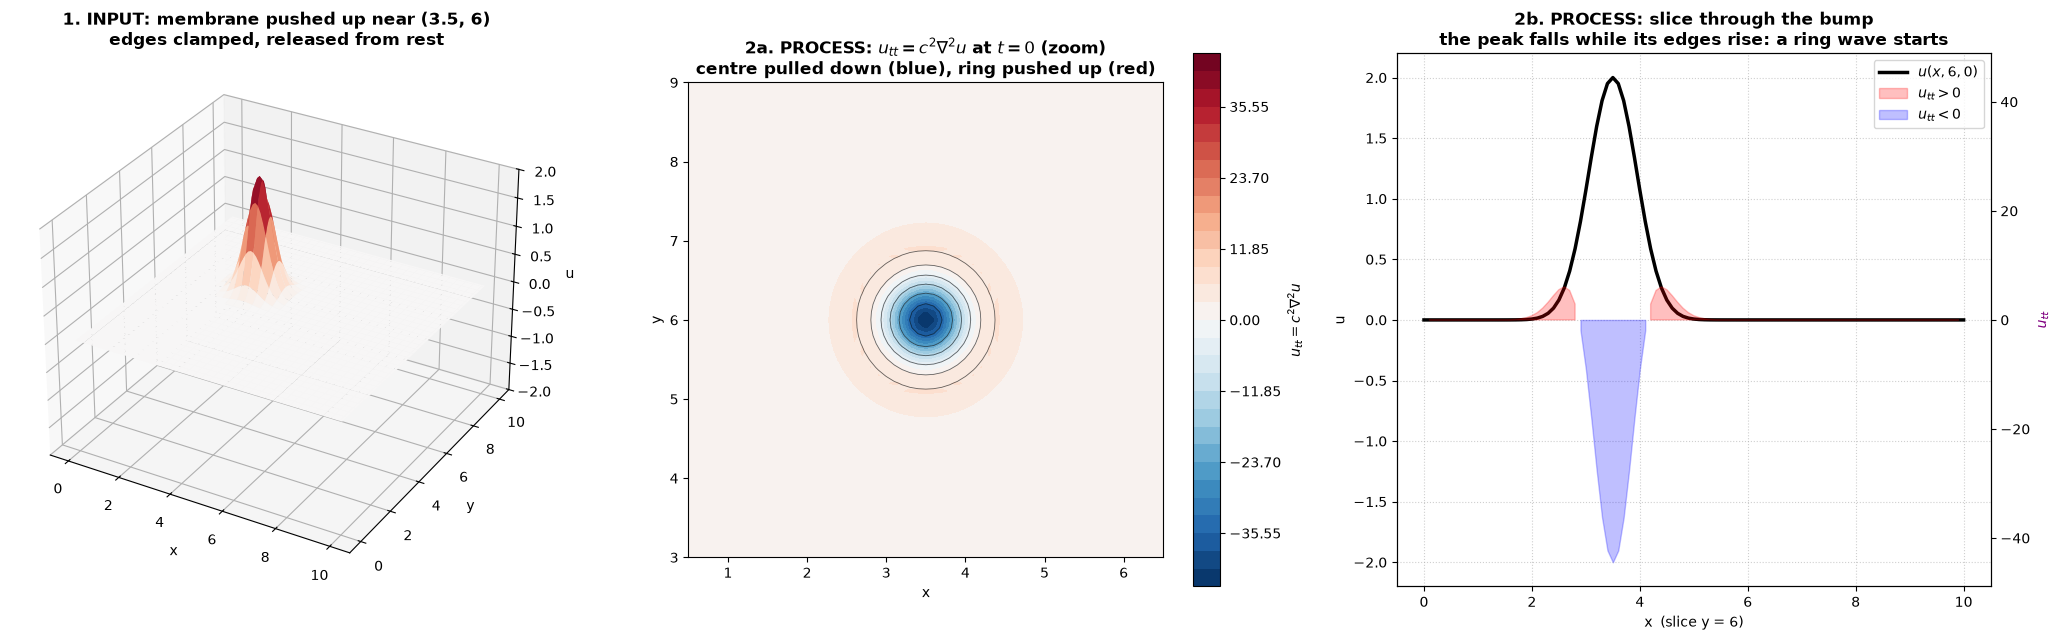

In [4]:
# 2D WAVE EQUATION, INPUT and PROCESS: initial membrane, Laplacian -> acceleration
import numpy as np
import matplotlib.pyplot as plt

lap0 = np.full_like(w0, np.nan)
lap0[1:-1, 1:-1] = lap5(w0) / h2**2
acc0 = c2**2 * lap0

fig = plt.figure(figsize=(21, 6.5))

# Panel 1: INPUT
ax1 = fig.add_subplot(1, 3, 1, projection='3d')
vmax = np.abs(w0).max()
ax1.plot_surface(X2, Y2, w0, cmap='RdBu_r', vmin=-vmax, vmax=vmax, edgecolor='none')
ax1.set_zlim(-vmax, vmax)
ax1.set_xlabel('x')
ax1.set_ylabel('y')
ax1.set_zlabel('u')
ax1.view_init(elev=30, azim=-60)
ax1.set_title('1. INPUT: membrane pushed up near (3.5, 6)\nedges clamped, released from rest',
              fontsize=12, fontweight='bold')

# Panel 2a: PROCESS (acceleration map)
ax2 = fig.add_subplot(1, 3, 2)
amax = np.nanmax(np.abs(acc0))
cf = ax2.contourf(X2, Y2, acc0, levels=np.linspace(-amax, amax, 31), cmap='RdBu_r')
ax2.contour(X2, Y2, w0, levels=6, colors='k', linewidths=0.6, alpha=0.6)
ax2.set_xlim(0.5, 6.5)
ax2.set_ylim(3, 9)
fig.colorbar(cf, ax=ax2, label=r'$u_{tt} = c^2\nabla^2 u$')
ax2.set_title(r'2a. PROCESS: $u_{tt} = c^2\nabla^2 u$ at $t = 0$ (zoom)' + '\n'
              + 'centre pulled down (blue), ring pushed up (red)', fontsize=12, fontweight='bold')

# Panel 2b: PROCESS (radial slice through the bump)
ax3 = fig.add_subplot(1, 3, 3)
row = np.argmin(np.abs(y2 - 6.0))
ax3.plot(x2, w0[row], 'k-', lw=2.5, label='$u(x, 6, 0)$')
ax3.set_ylabel('u')
ax3b = ax3.twinx()
a = acc0[row]
ax3b.fill_between(x2, a, 0, where=a > 0, color='red', alpha=0.25, label=r'$u_{tt} > 0$')
ax3b.fill_between(x2, a, 0, where=a < 0, color='blue', alpha=0.25, label=r'$u_{tt} < 0$')
amax_s = np.nanmax(np.abs(a)) * 1.1
ax3.set_ylim(-2.2, 2.2)
ax3b.set_ylim(-amax_s, amax_s)                     # both axes centred on zero
ax3b.set_ylabel(r'$u_{tt}$', color='purple')
h1, l1 = ax3.get_legend_handles_labels()
h2_, l2_ = ax3b.get_legend_handles_labels()
ax3.legend(h1 + h2_, l1 + l2_, loc='upper right')
ax3.set_xlabel('x  (slice y = 6)')
ax3.grid(True, linestyle=':', alpha=0.6)
ax3.set_title('2b. PROCESS: slice through the bump\nthe peak falls while its edges rise: a ring wave starts',
              fontsize=12, fontweight='bold')

for ax in (ax2,):
    ax.set_aspect('equal')
    ax.set_xlabel('x')
    ax.set_ylabel('y')

plt.tight_layout()
plt.show()

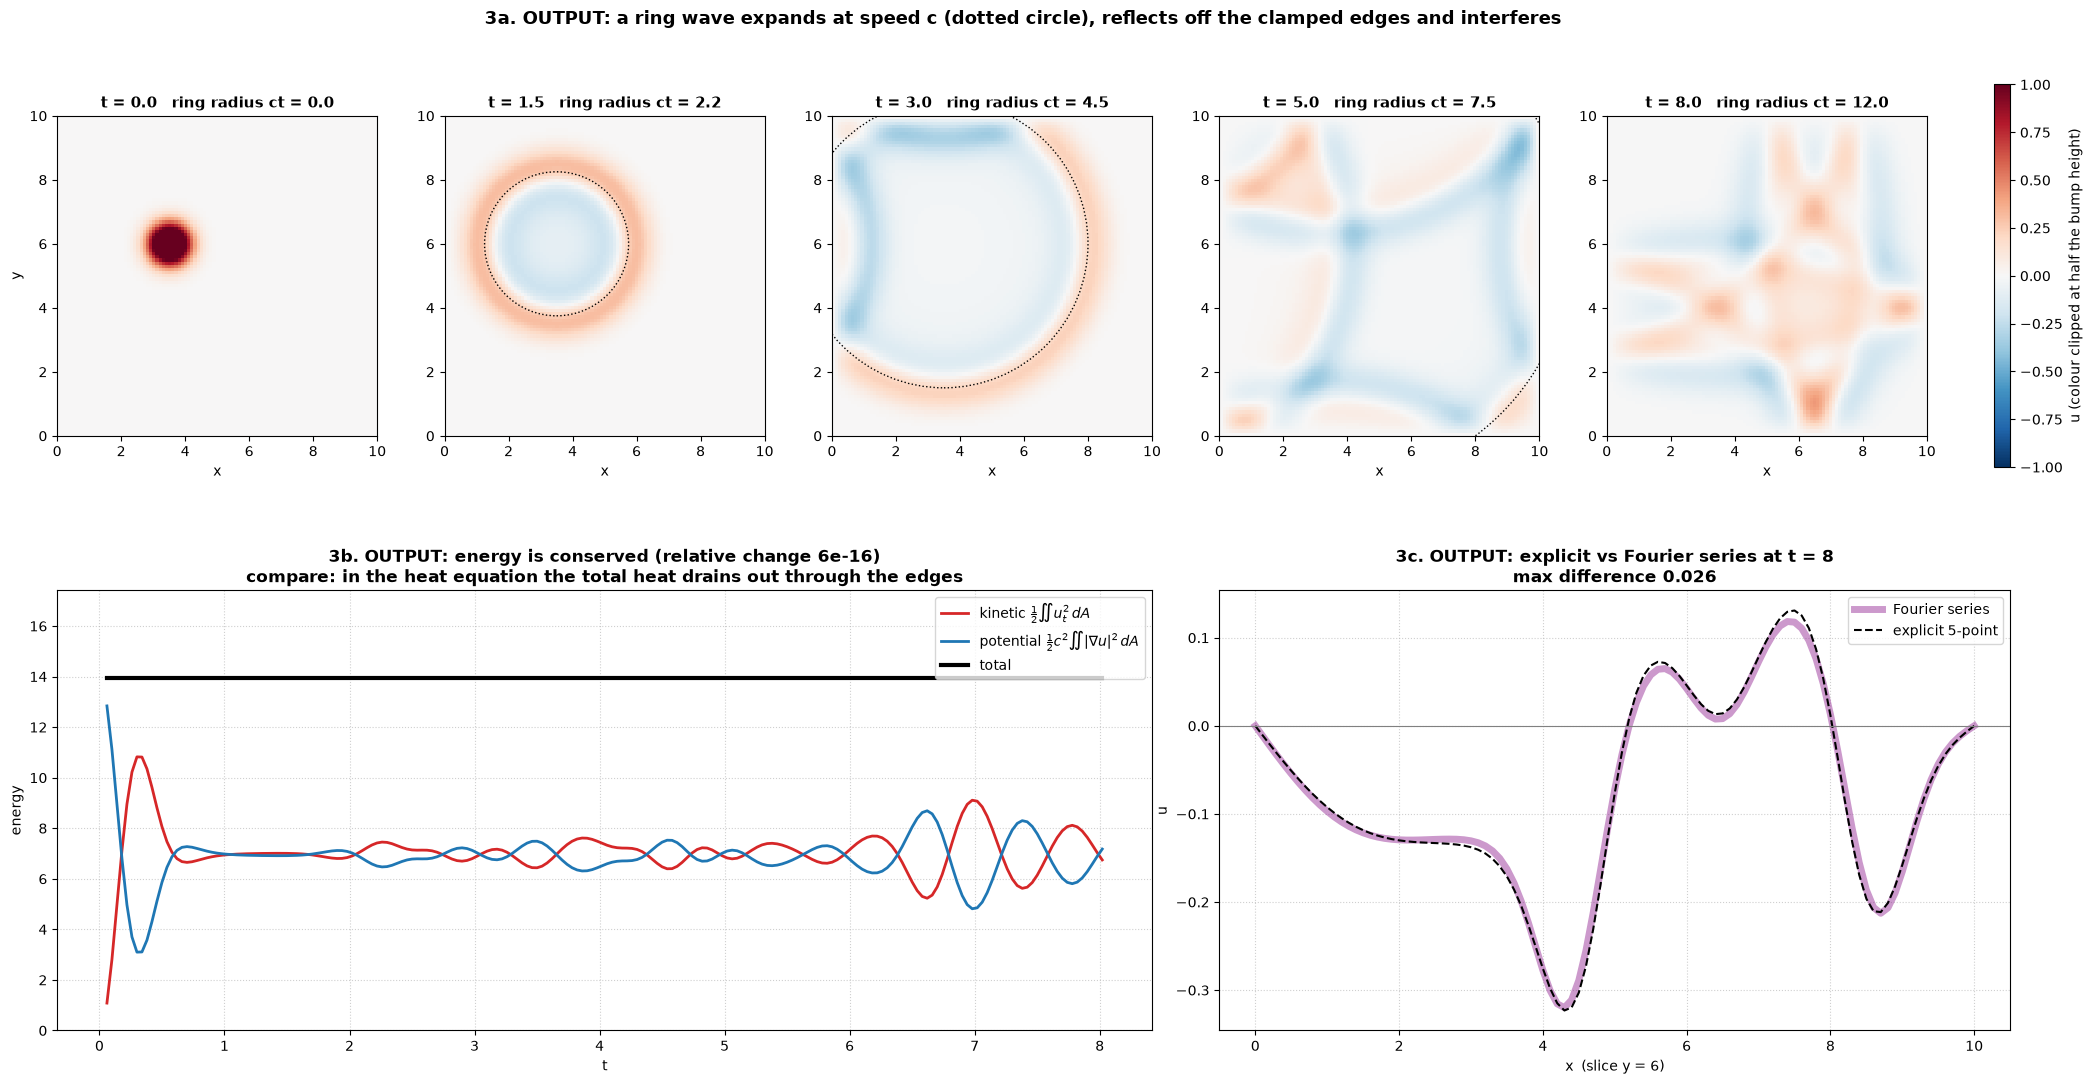

In [5]:
# 2D WAVE EQUATION, OUTPUT: ring waves, reflections, energy, comparison with the Fourier series
import numpy as np
import matplotlib.pyplot as plt

n_snap = len(snap2_times)
fig = plt.figure(figsize=(21, 11))
gs = fig.add_gridspec(2, n_snap + 1, width_ratios=[1] * n_snap + [0.05], height_ratios=[1, 1.15])
vmax = 0.5 * np.abs(w0).max()

for k, tt in enumerate(snap2_times):
    ax = fig.add_subplot(gs[0, k])
    im = ax.imshow(snaps2[tt], origin='lower', extent=[0, L2, 0, L2], cmap='RdBu_r', vmin=-vmax, vmax=vmax)
    ax.set_title(f't = {tt:.1f}   ring radius ct = {c2 * tt:.1f}', fontsize=11, fontweight='bold')
    if 0 < tt and c2 * tt < 9:
        ax.add_patch(plt.Circle((3.5, 6.0), c2 * tt, fill=False, ls=':', color='k', lw=1))
    ax.set_xlabel('x')
    if k == 0:
        ax.set_ylabel('y')
fig.colorbar(im, cax=fig.add_subplot(gs[0, n_snap]), label='u (colour clipped at half the bump height)')
fig.text(0.5, 0.975, '3a. OUTPUT: a ring wave expands at speed c (dotted circle), reflects off the clamped edges and interferes',
         ha='center', fontsize=13, fontweight='bold')

ax_e = fig.add_subplot(gs[1, :3])
ax_e.plot(t2_energy, KE2, color='tab:red', lw=2, label=r'kinetic $\frac{1}{2}\iint u_t^2\, dA$')
ax_e.plot(t2_energy, PE2, color='tab:blue', lw=2, label=r'potential $\frac{1}{2}c^2\iint |\nabla u|^2\, dA$')
ax_e.plot(t2_energy, E2, 'k-', lw=3, label='total')
ax_e.set_ylim(0, E2.max() * 1.25)
ax_e.set_xlabel('t')
ax_e.set_ylabel('energy')
ax_e.grid(True, linestyle=':', alpha=0.6)
ax_e.legend(loc='upper right')
ax_e.set_title(f'3b. OUTPUT: energy is conserved (relative change {(E2.max() - E2.min()) / E2[0]:.0e})\n'
               'compare: in the heat equation the total heat drains out through the edges',
               fontsize=12, fontweight='bold')

ax_c = fig.add_subplot(gs[1, 3:n_snap + 1])
row = np.argmin(np.abs(y2 - 6.0))
ax_c.plot(x2, w_exact_T[row], color='purple', lw=5, alpha=0.4, label='Fourier series')
ax_c.plot(x2, snaps2[T2_max][row], 'k--', lw=1.5, label='explicit 5-point')
ax_c.axhline(0, color='gray', lw=0.8)
ax_c.set_xlabel('x  (slice y = 6)')
ax_c.set_ylabel('u')
ax_c.grid(True, linestyle=':', alpha=0.6)
ax_c.legend(loc='upper right')
ax_c.set_title(f'3c. OUTPUT: explicit vs Fourier series at t = {T2_max:.0f}\n'
               f'max difference {np.abs(snaps2[T2_max] - w_exact_T).max():.3f}', fontsize=12, fontweight='bold')

plt.subplots_adjust(top=0.92, bottom=0.06, left=0.04, right=0.97, hspace=0.3, wspace=0.25)
plt.show()

## Part 3: Heat vs wave, the same bump

Both equations start from the same bump on the same 1D domain with ends held at zero. Both are computed from their exact series solutions:

$$\text{heat: } u = \sum B_n \sin(k_n x)\, e^{-\alpha k_n^2 t} \qquad\qquad \text{wave: } u = \sum B_n \sin(k_n x)\, \cos(c\, k_n t)$$

The only difference is $e^{-\alpha k_n^2 t}$ (every mode decays, fine detail fastest) versus $\cos(c k_n t)$ (every mode oscillates forever). That one change is the difference between smoothing and travelling.

series reproduces the bump: max |u(x,0) - f| = 1.9e-13
at t = 13.33: heat peak 0.064, wave back to its start (max |u - f| = 1.9e-13)


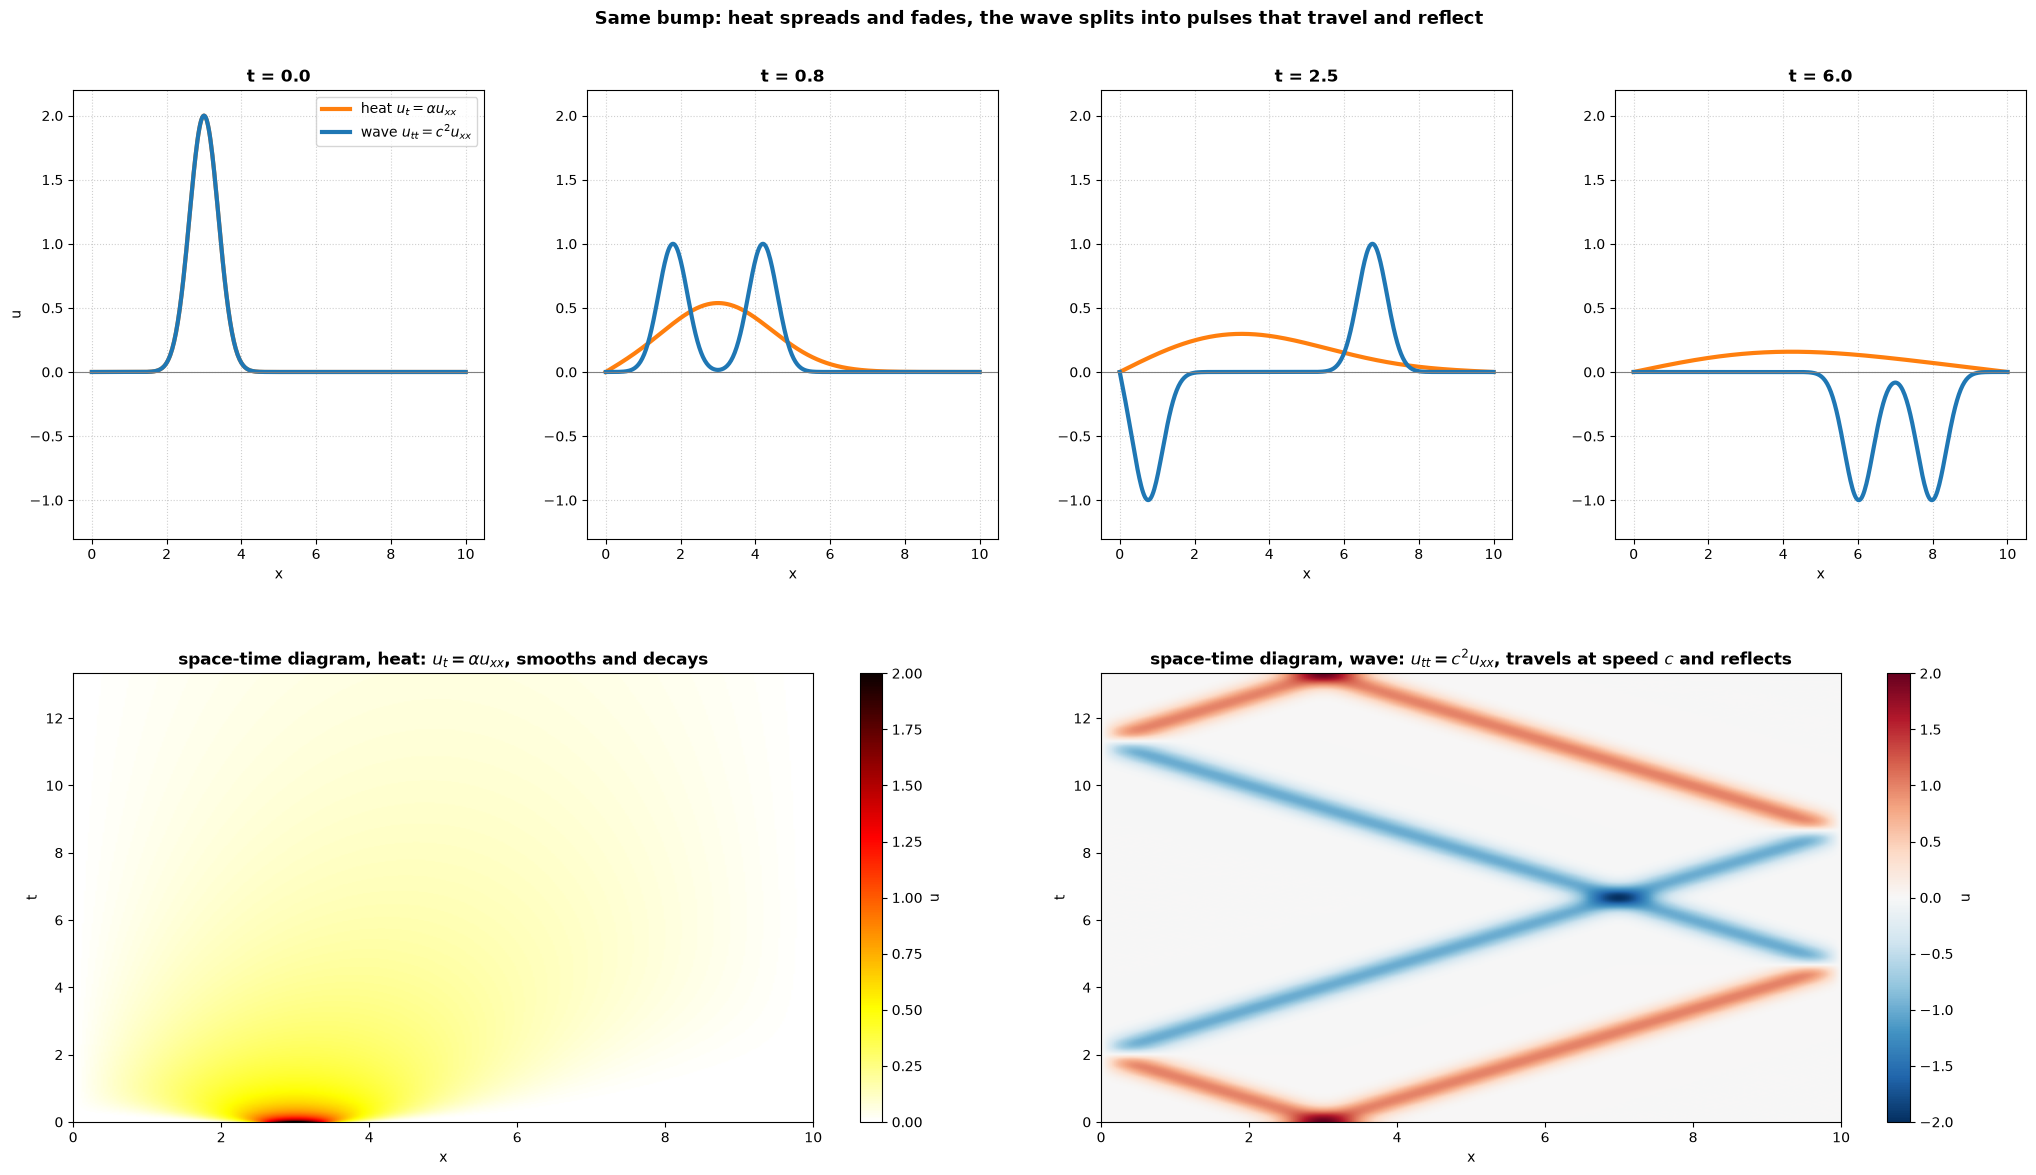

In [6]:
# HEAT vs WAVE: same initial bump, same Laplacian, different time derivative
import numpy as np
import matplotlib.pyplot as plt

trap = getattr(np, 'trapezoid', None) or getattr(np, 'trapz')

L3, alpha3, c3 = 10.0, 1.2, 1.5
x3 = np.linspace(0, L3, 401)
f3 = 2.0 * np.exp(-((x3 - 3.0)**2) / 0.3)
n_modes = np.arange(1, 201)
k3 = n_modes * np.pi / L3
S = np.sin(np.outer(x3, k3))                                  # (x, modes)
B3 = 2 / L3 * trap(f3[:, None] * S, x3, axis=0)               # sine coefficients

t3 = np.linspace(0, 2 * L3 / c3, 400)
heat = S @ (B3[:, None] * np.exp(-alpha3 * np.outer(k3**2, t3)))   # (x, t)
wave = S @ (B3[:, None] * np.cos(c3 * np.outer(k3, t3)))

print(f"series reproduces the bump: max |u(x,0) - f| = {np.abs(wave[:, 0] - f3).max():.1e}")
print(f"at t = {t3[-1]:.2f}: heat peak {heat[:, -1].max():.3f}, wave back to its start "
      f"(max |u - f| = {np.abs(wave[:, -1] - f3).max():.1e})")

fig = plt.figure(figsize=(21, 12))
gs = fig.add_gridspec(2, 4)
times = [0.0, 0.8, 2.5, 6.0]
for k, tt in enumerate(times):
    ax = fig.add_subplot(gs[0, k])
    j = np.argmin(np.abs(t3 - tt))
    ax.plot(x3, heat[:, j], color='tab:orange', lw=3, label=r'heat $u_t = \alpha u_{xx}$')
    ax.plot(x3, wave[:, j], color='tab:blue', lw=3, label=r'wave $u_{tt} = c^2 u_{xx}$')
    ax.axhline(0, color='gray', lw=0.8)
    ax.set_ylim(-1.3, 2.2)
    ax.set_xlabel('x')
    ax.grid(True, linestyle=':', alpha=0.6)
    ax.set_title(f't = {t3[j]:.1f}', fontsize=12, fontweight='bold')
    if k == 0:
        ax.set_ylabel('u')
        ax.legend(loc='upper right')
fig.text(0.5, 0.975, 'Same bump: heat spreads and fades, the wave splits into pulses that travel and reflect',
         ha='center', fontsize=13, fontweight='bold')

for k, (data, name, cmap) in enumerate([(heat, r'heat: $u_t = \alpha u_{xx}$, smooths and decays', 'hot_r'),
                                        (wave, r'wave: $u_{tt} = c^2 u_{xx}$, travels at speed $c$ and reflects', 'RdBu_r')]):
    ax = fig.add_subplot(gs[1, 2 * k:2 * k + 2])
    vmax = np.abs(f3).max()
    im = ax.imshow(data.T, origin='lower', aspect='auto', extent=[0, L3, 0, t3[-1]], cmap=cmap,
                   vmin=0 if k == 0 else -vmax, vmax=vmax)
    ax.set_xlabel('x')
    ax.set_ylabel('t')
    fig.colorbar(im, ax=ax, label='u')
    ax.set_title('space-time diagram, ' + name, fontsize=12, fontweight='bold')

plt.subplots_adjust(top=0.92, bottom=0.06, left=0.04, right=0.97, hspace=0.3, wspace=0.25)
plt.show()